# X-IIoTID — 04. Full-data missingness and feature-collision verification

**Project:** J26-CS-336 · network-flow model at IIoT edge gateways  
**Input:** original `X-IIoTID dataset.csv` (read only)  
**Output:** Git-connected `network_flow_v2/reports` and `docs` (the raw data is not copied into Git).

### Why do this?
Your earlier **42,500-row sample** found **60 binary-label conflicts** using **only eight network features**, not all 19. That is a warning, not proof that X-IIoTID is unsuitable. We now re-check **all 820,834 rows**, comparing:
- **Basic 8:** Protocol, Service, Duration, Scr_bytes, Des_bytes, Scr_pkts, Des_pkts, Conn_state.
- **Extended 19:** all current network-core candidates (including some derived fields).

We also ask whether missing byte/packet values occur more often in attack rows than normal rows. A detector might otherwise learn a **dataset shortcut** rather than real attack behaviour.

**Simple example:** If missing packet counts happen mostly during malicious captures, a model might identify *how the data was recorded* instead of detecting the actual attack.

> This notebook **does not train models**, create train/validation/test partitions, alter raw CSVs, prove APT-stage recognition or confirm edge-gateway measurability. Identical numeric/string representation is compared as recorded after whitespace trimming; placeholder spellings are normalized. Hash collisions are theoretically possible but extremely unlikely (128-bit BLAKE2b). Scratch database files under `data/interim` are temporary and should stay ignored by Git.


In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import re
import sqlite3
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Reports always go to your Git-connected V2 workspace (when it exists).
GIT_ROOT = Path(r'D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2')
OLD_ROOT = Path(r'D:\J26-CS-336-Network-Flow-V2\network_flow_v2')

if GIT_ROOT.is_dir():
    ROOT = GIT_ROOT
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / 'README.md').exists() and (p / 'notebooks').is_dir()), None)
    if ROOT is None:
        raise FileNotFoundError('Open this notebook from your Git-connected network_flow_v2 project folder.')

relative_csv = Path('data/raw/x_iiotid/X-IIoTID dataset.csv')
CSV = ROOT / relative_csv
if not CSV.is_file():
    CSV = OLD_ROOT / relative_csv
if not CSV.is_file():
    raise FileNotFoundError('X-IIoTID dataset.csv not found under Git or previous local V2 data/raw/x_iiotid folder.')

FIG = ROOT / 'reports/figures'
AUDIT = ROOT / 'reports/audits'
DOCS = ROOT / 'docs'
TMP = ROOT / 'data/interim'
for d in (FIG, AUDIT, DOCS, TMP):
    d.mkdir(parents=True, exist_ok=True)

DB_PATH = TMP / 'x_iiotid_full_collision_gate_v1.sqlite'
CHUNK_SIZE = 40_000
PLACEHOLDERS = {'', '-', '?', 'n/a', 'na', 'nan', 'none', 'null', 'missing', 'unknown'}

print('Read-only dataset:', CSV)
print('Reports saved to:', ROOT)
print('Scratch database (do not commit):', DB_PATH)
print('Git-connected output root:', ROOT == GIT_ROOT)


Read-only dataset: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2\data\raw\x_iiotid\X-IIoTID dataset.csv
Reports saved to: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2
Scratch database (do not commit): D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2\data\interim\x_iiotid_full_collision_gate_v1.sqlite
Git-connected output root: True


## A. Verify the exact feature names

The current **19** are *candidates*, not approved model inputs. `class1`, `class2`, `class3`, IPs, dates, alerts, and host telemetry are not in the feature signatures. The 19-column comparison simply tests whether more network context reduces collisions.

In [2]:
def colkey(name):
    return re.sub(r'[^a-z0-9]+', '', name.casefold())

header = pd.read_csv(CSV, nrows=0).columns.tolist()
lookup = {colkey(c): c for c in header}

def columns_required(names):
    absent = [n for n in names if colkey(n) not in lookup]
    if absent:
        raise ValueError(f'Required X-IIoTID columns missing: {absent}')
    return [lookup[colkey(n)] for n in names]

BASIC8 = columns_required([
    'Protocol', 'Service', 'Duration', 'Scr_bytes',
    'Des_bytes', 'Scr_pkts', 'Des_pkts', 'Conn_state'
])
CORE19 = columns_required([
    'Protocol', 'Service', 'Duration', 'Scr_bytes', 'Des_bytes',
    'Conn_state', 'is_syn_only', 'Is_SYN_ACK', 'is_pure_ack',
    'is_with_payload', 'FIN or RST', 'Scr_pkts', 'Scr_ip_bytes',
    'Des_pkts', 'Des_ip_bytes', 'total_bytes', 'total_packet',
    'paket_rate', 'byte_rate'
])
C2, C3 = columns_required(['class2', 'class3'])
FEATURES = list(dict.fromkeys(CORE19))
USECOLS = list(dict.fromkeys(FEATURES + [C2, C3]))

assert len(BASIC8) == 8 and len(CORE19) == 19
assert all(c not in FEATURES for c in (C2, C3))
print('Basic collision inputs (8):', BASIC8)
print('Extended collision inputs (19):', CORE19)
print('All dataset columns:', len(header))


Basic collision inputs (8): ['Protocol', 'Service', 'Duration', 'Scr_bytes', 'Des_bytes', 'Scr_pkts', 'Des_pkts', 'Conn_state']
Extended collision inputs (19): ['Protocol', 'Service', 'Duration', 'Scr_bytes', 'Des_bytes', 'Conn_state', 'is_syn_only', 'Is_SYN_ACK', 'is_pure_ack', 'is_with_payload', 'FIN or RST', 'Scr_pkts', 'Scr_ip_bytes', 'Des_pkts', 'Des_ip_bytes', 'total_bytes', 'total_packet', 'paket_rate', 'byte_rate']
All dataset columns: 68


## B. Scan **all rows** without loading the entire CSV into RAM

This step maintains two disk-backed group-count tables (8-feature and 19-feature). The database is stored under `data/interim` (ignored by Git); only compact summaries and figures are exported. Running this cell again replaces the **scratch database**, not the original dataset.

In [3]:
def normalize(series: pd.Series) -> pd.Series:
    s = series.fillna('').astype(str).str.strip()
    return s.mask(s.str.casefold().isin(PLACEHOLDERS), '<MISSING>')

def digest_values(values) -> str:
    # Length-prefixed encoding avoids ambiguity between adjacent string fields.
    hasher = hashlib.blake2b(digest_size=16)
    for v in values:
        part = str(v).encode('utf-8')
        hasher.update(len(part).to_bytes(4, 'big'))
        hasher.update(part)
    return hasher.hexdigest()

def signatures(frame, feature_names):
    return [digest_values(row) for row in frame[feature_names].itertuples(index=False, name=None)]

if DB_PATH.exists():
    DB_PATH.unlink()  # This is a *scratch output*, not the source CSV.
con = sqlite3.connect(str(DB_PATH))
con.execute('PRAGMA journal_mode=MEMORY')
con.execute('PRAGMA synchronous=OFF')
for table in ('basic8', 'core19'):
    con.execute(f"""CREATE TABLE {table} (
        signature TEXT PRIMARY KEY,
        normal_count INTEGER NOT NULL DEFAULT 0,
        attack_count INTEGER NOT NULL DEFAULT 0
    )""")

UPSERT = """INSERT INTO {table} (signature,normal_count,attack_count)
VALUES (?,?,?)
ON CONFLICT(signature) DO UPDATE SET
normal_count=normal_count+excluded.normal_count,
attack_count=attack_count+excluded.attack_count"""

missing_by_binary = {lab: Counter() for lab in ('Normal', 'Attack')}
missing_by_class2 = {}
label_total = Counter()
class2_total = Counter()
scanned = 0

try:
    for part in pd.read_csv(CSV, chunksize=CHUNK_SIZE, usecols=USECOLS,
                            dtype=str, keep_default_na=False, low_memory=False):
        labels = part[C3].fillna('').str.strip().str.casefold().map(
            {'normal': 'Normal', 'attack': 'Attack'})
        if labels.isna().any():
            bad = part.loc[labels.isna(), C3].value_counts().head(5).to_dict()
            raise ValueError(f'Unexpected class3 values: {bad}')
        cats = part[C2].fillna('').str.strip()
        normalized = pd.DataFrame({c: normalize(part[c]) for c in FEATURES}, index=part.index)
        miss = normalized.eq('<MISSING>')
        
        # Full-data missingness by binary label and class2 category.
        b_counts = miss.groupby(labels).sum()
        for lab, row in b_counts.iterrows():
            missing_by_binary[lab].update({k: int(v) for k, v in row.items()})
        c_counts = miss[BASIC8].groupby(cats).sum()
        for cat, row in c_counts.iterrows():
            if cat not in missing_by_class2:
                missing_by_class2[cat] = Counter()
            missing_by_class2[cat].update({k: int(v) for k, v in row.items()})
        label_total.update(labels.value_counts().to_dict())
        class2_total.update(cats.value_counts().to_dict())
        
        for table, subset in (('basic8', BASIC8), ('core19', CORE19)):
            sig = pd.Series(signatures(normalized, subset), index=part.index, name='signature')
            counts = pd.DataFrame({'signature': sig, 'label': labels.values})                .groupby(['signature', 'label']).size().unstack(fill_value=0)                .reindex(columns=['Normal', 'Attack'], fill_value=0)
            items = [(str(idx), int(r[0]), int(r[1]))
                     for idx, r in zip(counts.index, counts.to_numpy())]
            con.executemany(UPSERT.format(table=table), items)
        con.commit()
        scanned += len(part)
        print(f'Processed {scanned:,} records', flush=True)
finally:
    con.commit()

print('Full dataset rows scanned:', f'{scanned:,}')
print('Binary labels:', dict(label_total))
print('Broad categories:', len(class2_total))


Processed 40,000 records
Processed 80,000 records
Processed 120,000 records
Processed 160,000 records
Processed 200,000 records
Processed 240,000 records
Processed 280,000 records
Processed 320,000 records
Processed 360,000 records
Processed 400,000 records
Processed 440,000 records
Processed 480,000 records
Processed 520,000 records
Processed 560,000 records
Processed 600,000 records
Processed 640,000 records
Processed 680,000 records
Processed 720,000 records
Processed 760,000 records
Processed 800,000 records
Processed 820,834 records
Full dataset rows scanned: 820,834
Binary labels: {'Normal': 421417, 'Attack': 399417}
Broad categories: 10


## C. Collision findings for **8 vs 19 inputs**

- **Repeated-feature group:** at least two records share the same selected features.
- **Conflicting-label group:** such a group contains both Normal and Attack labels.
- **Records in conflicting groups:** total number of records in those ambiguous groups, **not necessarily the number of incorrect labels**.

These are not exact full-row duplicates: groups are defined by *only the selected network columns*.

In [4]:
def summarize_table(table):
    sql = f"""SELECT COUNT(*) AS unique_groups,
       COALESCE(SUM(normal_count+attack_count),0) AS row_count,
       COALESCE(SUM(CASE WHEN normal_count+attack_count>1 THEN normal_count+attack_count ELSE 0 END),0) AS repeated_records,
       COALESCE(SUM(CASE WHEN normal_count>0 AND attack_count>0 THEN 1 ELSE 0 END),0) AS conflicting_groups,
       COALESCE(SUM(CASE WHEN normal_count>0 AND attack_count>0 THEN normal_count+attack_count ELSE 0 END),0) AS conflicting_records,
       COALESCE(MAX(normal_count+attack_count),0) AS max_group_size
       FROM {table}"""
    return pd.read_sql_query(sql, con).iloc[0].astype(int).to_dict()

stats = {'basic8': summarize_table('basic8'), 'core19': summarize_table('core19')}
for k, item in stats.items():
    assert item['row_count'] == scanned, f'Row loss in {k}'

comparison = pd.DataFrame([
    {'feature_set': 'Basic 8', 'features': len(BASIC8), **stats['basic8']},
    {'feature_set': 'Core 19', 'features': len(CORE19), **stats['core19']},
])
display(comparison)

# Show group sizes only; no source IPs, raw rows or sensitive identifiers.
def top_groups(table, n=12, conflicts_only=False):
    where = 'WHERE normal_count>0 AND attack_count>0' if conflicts_only else ''
    return pd.read_sql_query(f"""SELECT normal_count, attack_count,
       normal_count+attack_count AS group_size
       FROM {table} {where}
       ORDER BY group_size DESC LIMIT {int(n)}""", con)

print('Largest BASIC8 groups:')
display(top_groups('basic8', 10))
print('Largest conflicting CORE19 groups:')
display(top_groups('core19', 10, True))


,feature_set,features,unique_groups,row_count,repeated_records,conflicting_groups,conflicting_records,max_group_size
0,Basic 8,8,417865,820834,446309,2000,92954,64533
1,Core 19,19,419378,820834,445336,1969,21866,64194


Largest BASIC8 groups:


,normal_count,attack_count,group_size
0,2,64531,64533
1,0,4357,4357
2,0,2426,2426
3,2186,7,2193
4,0,1982,1982
5,0,1818,1818
6,0,1774,1774
7,1687,0,1687
8,1652,0,1652
9,1649,0,1649


Largest conflicting CORE19 groups:


,normal_count,attack_count,group_size
0,496,324,820
1,250,11,261
2,45,202,247
3,185,1,186
4,138,1,139
5,136,1,137
6,135,1,136
7,96,25,121
8,118,1,119
9,104,5,109


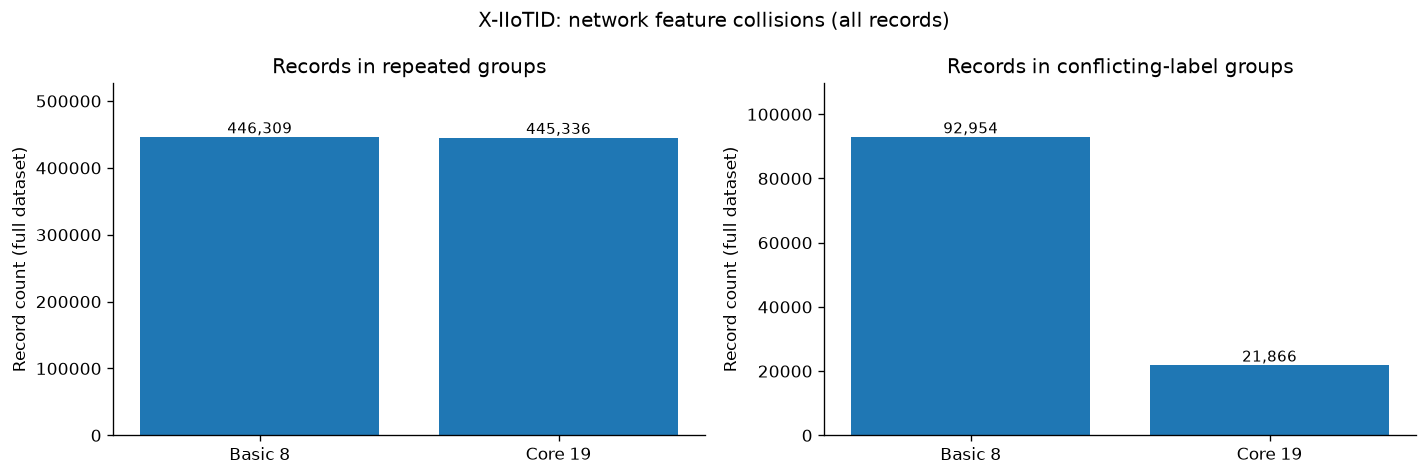

Saved: reports\figures\x_iiotid_full_feature_collision_comparison_v1.png


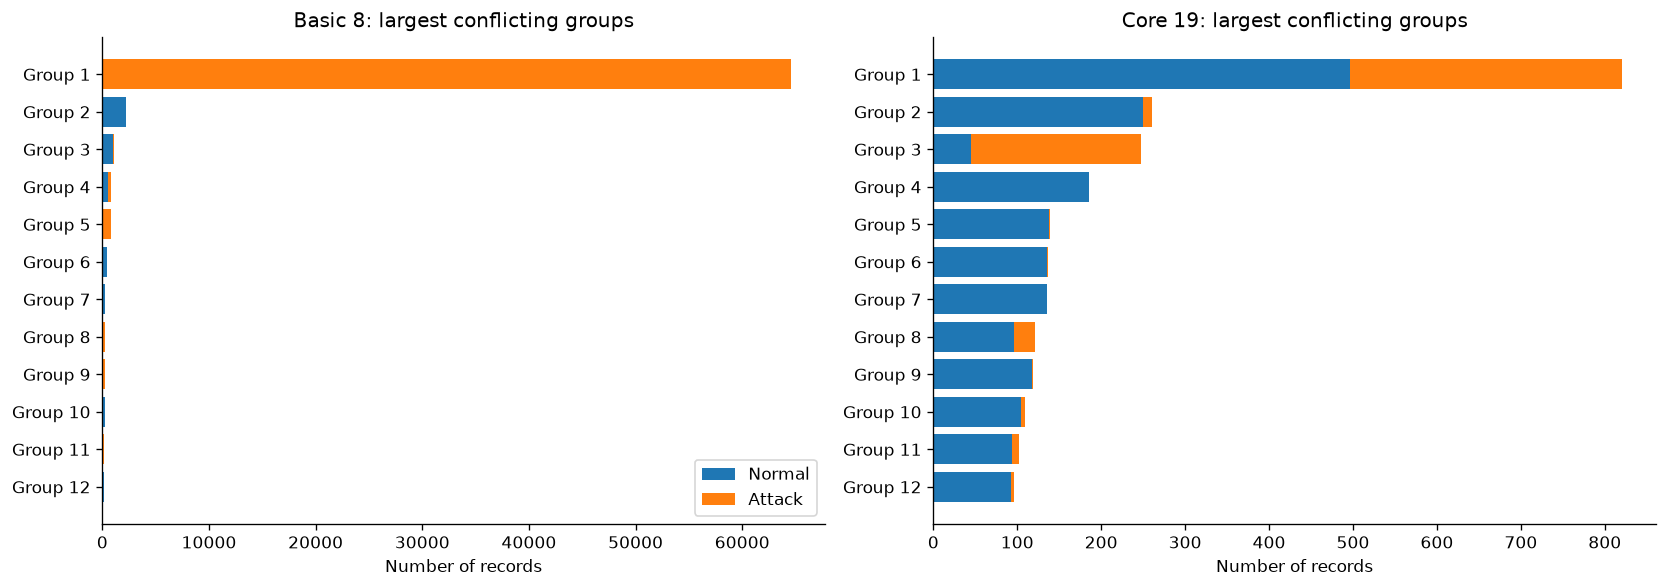

Saved: reports\figures\x_iiotid_full_conflicting_label_groups_v1.png


In [5]:
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 180,
                     'axes.spines.top': False, 'axes.spines.right': False})

def output_figure(filename):
    p = FIG / filename
    plt.savefig(p, bbox_inches='tight')
    plt.show()
    print('Saved:', p.relative_to(ROOT))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes,
        ['repeated_records', 'conflicting_records'],
        ['Records in repeated groups', 'Records in conflicting-label groups']):
    bars = ax.bar(['Basic 8', 'Core 19'], [stats[k][metric] for k in ('basic8', 'core19')])
    ax.set_title(title)
    ax.set_ylabel('Record count (full dataset)')
    ax.ticklabel_format(style='plain', axis='y')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f'{bar.get_height():,.0f}', ha='center', va='bottom', fontsize=9)
    ax.set_ylim(0, max(1, max(stats[k][metric] for k in ('basic8', 'core19'))) * 1.18)
fig.suptitle('X-IIoTID: network feature collisions (all records)')
fig.tight_layout()
output_figure('x_iiotid_full_feature_collision_comparison_v1.png')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, key, title in zip(axes, ('basic8','core19'), ('Basic 8','Core 19')):
    top = top_groups(key, 12, conflicts_only=True)
    if top.empty:
        ax.text(0.5, 0.5, 'No conflicting binary-label groups',
                ha='center', va='center', transform=ax.transAxes)
    else:
        y = np.arange(len(top))
        ax.barh(y, top.normal_count, label='Normal')
        ax.barh(y, top.attack_count, left=top.normal_count, label='Attack')
        ax.set_yticks(y, [f'Group {i+1}' for i in range(len(top))])
        ax.invert_yaxis()
        ax.set_xlabel('Number of records')
    ax.set_title(f'{title}: largest conflicting groups')
axes[0].legend(loc='lower right')
fig.tight_layout()
output_figure('x_iiotid_full_conflicting_label_groups_v1.png')


## D. Missingness comparison: Normal vs Attack, and broad categories

A feature can be predictive because its **value** is meaningful, or because a dataset has systematically **missing values** in one class. The latter must be checked carefully for capture artifacts and evaluation leakage.

**Everyday example:** if all exam solutions happen to be printed on blue paper, a student might use paper colour to guess answers instead of learning the subject.

Missingness by binary label: biggest percentage-point differences (full CSV)


,feature,Normal,Attack,abs_difference_pp
2,Duration,1.83,17.04,15.20
4,Des_bytes,19.99,34.96,14.98
3,Scr_bytes,19.99,34.96,14.98
17,paket_rate,19.99,34.96,14.98
15,total_bytes,19.99,34.96,14.98
18,byte_rate,19.99,34.96,14.98
16,total_packet,18.49,18.73,0.25
12,Scr_ip_bytes,18.49,18.73,0.25
11,Scr_pkts,18.49,18.73,0.25
13,Des_pkts,18.49,18.73,0.25


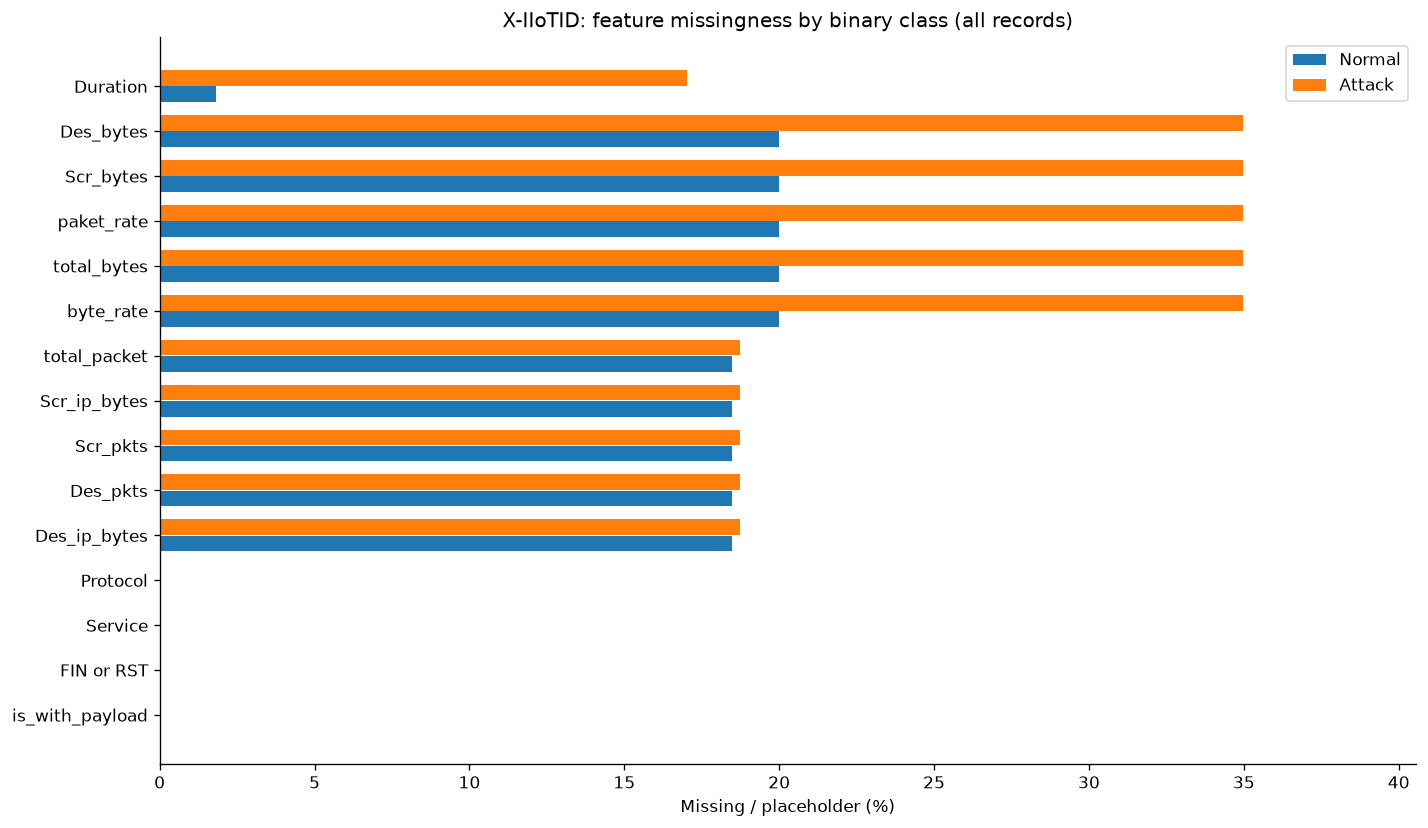

Saved: reports\figures\x_iiotid_full_missingness_by_binary_label_v1.png
Basic 8: missingness by class2 broad category (percent)


,Protocol,Service,Duration,Scr_bytes,Des_bytes,Scr_pkts,Des_pkts,Conn_state
class2,,,,,,,,
Normal,0.00,0.0,1.83,19.99,19.99,18.49,18.49,0.0
RDOS,0.00,0.0,45.44,45.44,45.44,0.00,0.00,0.0
Reconnaissance,0.00,0.0,0.57,26.27,26.27,25.83,25.83,0.0
Weaponization,0.00,0.0,1.52,40.84,40.84,40.84,40.84,0.0
Lateral _movement,0.00,0.0,0.09,19.35,19.35,19.27,19.27,0.0
Exfiltration,0.00,0.0,0.05,26.51,26.51,26.51,26.51,0.0
Tampering,0.00,0.0,26.08,26.08,26.08,26.08,26.08,0.0
C&C,0.00,0.0,18.37,18.37,18.37,17.95,17.95,0.0
Exploitation,0.00,0.0,3.09,16.68,16.68,14.65,14.65,0.0


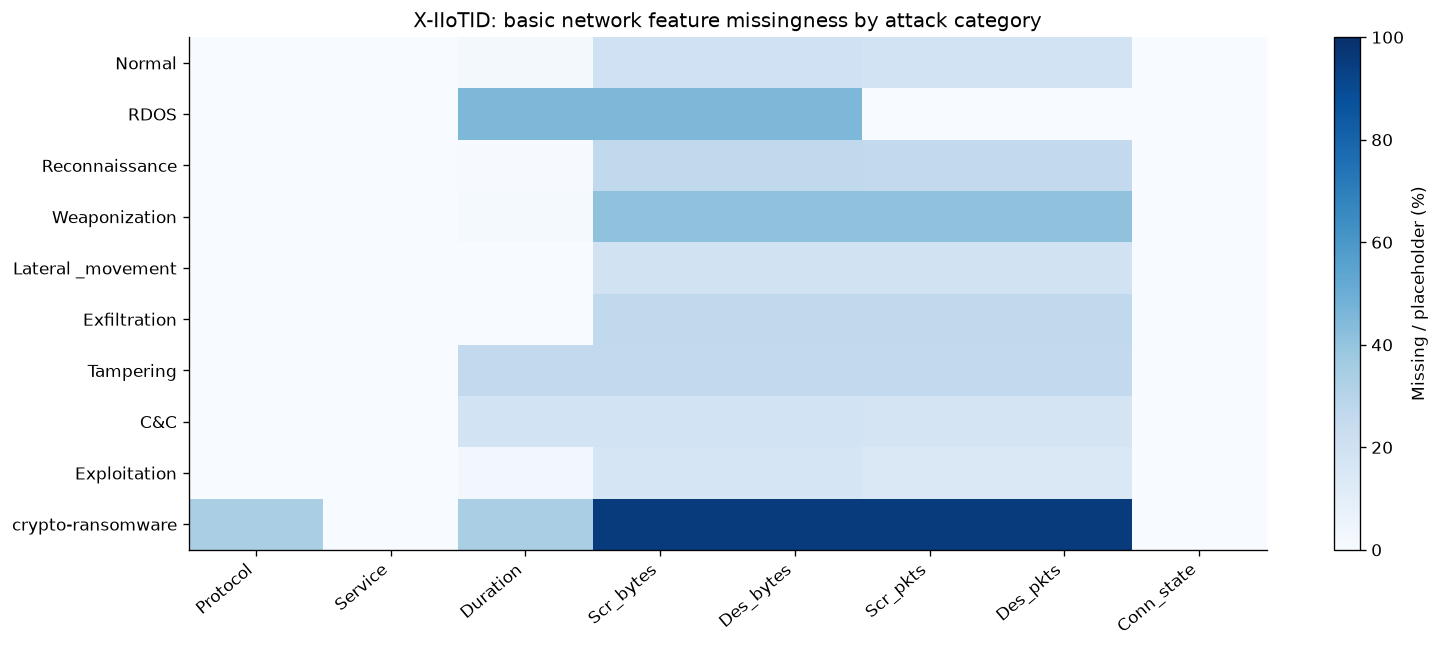

Saved: reports\figures\x_iiotid_full_missingness_by_class2_v1.png


In [6]:
missing_binary_pct = pd.DataFrame({
    lab: {c: 100 * missing_by_binary[lab][c] / label_total[lab]
          for c in FEATURES} for lab in ('Normal','Attack')
})
missing_binary_pct.index.name = 'feature'
missing_binary_pct = missing_binary_pct.reset_index()
missing_binary_pct['abs_difference_pp'] = (missing_binary_pct['Normal'] - missing_binary_pct['Attack']).abs()
missing_binary_pct = missing_binary_pct.sort_values('abs_difference_pp', ascending=False)
print('Missingness by binary label: biggest percentage-point differences (full CSV)')
display(missing_binary_pct.head(19).round(2))

ranking = missing_binary_pct.head(15).iloc[::-1]
y = np.arange(len(ranking))
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(y - 0.18, ranking['Normal'], height=0.35, label='Normal')
ax.barh(y + 0.18, ranking['Attack'], height=0.35, label='Attack')
ax.set_yticks(y, ranking['feature'])
ax.set_xlim(0, max(3, float(ranking[['Normal','Attack']].max().max()) * 1.16))
ax.set_xlabel('Missing / placeholder (%)')
ax.set_title('X-IIoTID: feature missingness by binary class (all records)')
ax.legend()
fig.tight_layout()
output_figure('x_iiotid_full_missingness_by_binary_label_v1.png')

ordered_categories = [c for c, _ in class2_total.most_common()]
missing_class2 = pd.DataFrame(index=ordered_categories, columns=BASIC8, dtype=float)
for cat in ordered_categories:
    for col in BASIC8:
        missing_class2.loc[cat, col] = (
            100 * missing_by_class2[cat][col] / class2_total[cat])
missing_class2.index.name = C2
print('Basic 8: missingness by class2 broad category (percent)')
display(missing_class2.round(2))

fig, ax = plt.subplots(figsize=(13, max(5.5, len(ordered_categories)*0.55)))
img = ax.imshow(missing_class2.to_numpy(), vmin=0, vmax=100,
                cmap='Blues', aspect='auto')
ax.set_xticks(np.arange(len(BASIC8)), BASIC8, rotation=40, ha='right')
ax.set_yticks(np.arange(len(ordered_categories)), ordered_categories)
ax.set_title('X-IIoTID: basic network feature missingness by attack category')
fig.colorbar(img, ax=ax, label='Missing / placeholder (%)')
fig.tight_layout()
output_figure('x_iiotid_full_missingness_by_class2_v1.png')


## E. Save evidence and a decision gate

Interpret with care:
- Missingness associated with attacks **may** indicate capture/collection artifacts, not necessarily proof of leakage.
- Moving from 8 to 19 features may reduce collisions, **but does not prove those features are safe**. Some derived fields may depend on unavailable sensor or capture details.
- The future 70/15/15 split still needs **session/device/time/source grouping** and independent tests. Neither feature hashing nor random splitting guarantees generalization.


In [7]:
comparison_path = AUDIT / 'x_iiotid_full_feature_collision_comparison_v1.csv'
binary_path = AUDIT / 'x_iiotid_full_missingness_by_binary_label_v1.csv'
class2_path = AUDIT / 'x_iiotid_full_missingness_by_class2_v1.csv'
json_path = AUDIT / 'x_iiotid_full_collision_missingness_gate_v1.json'
md_path = DOCS / 'X_IIOTID_FULL_COLLISION_MISSINGNESS_GATE_V1.md'

comparison.to_csv(comparison_path, index=False)
missing_binary_pct.to_csv(binary_path, index=False)
missing_class2.to_csv(class2_path)

summary = {
    'dataset': CSV.name,
    'all_records_scanned': int(scanned),
    'phase': 'feature-ambiguity and missingness analysis BEFORE splits/models',
    'hash_method': 'BLAKE2b-128; length-prefixed canonical cell strings',
    'normalization': 'strip cell whitespace and map listed placeholders to <MISSING>; do not collapse numeric representations',
    'dataset_split_created': False,
    'model_trained': False,
    'gateway_features_semantically_verified': False,
    'class3_counts': {k:int(v) for k,v in label_total.items()},
    'feature_sets': {'basic8': BASIC8, 'core19': CORE19},
    'collision_summary': stats,
    'missingness_class3_percentage': {
        str(row.feature): {'Normal':round(float(row.Normal),4),
                           'Attack':round(float(row.Attack),4),
                           'abs_difference_pp':round(float(row.abs_difference_pp),4)}
        for row in missing_binary_pct.itertuples(index=False)
    },
    'next_gate': 'Review collisions, verify feature semantics and per-scenario/missingness shortcuts; then define related-record-safe train/validation/test partitions.'
}
json_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')

md = f"""# X-IIoTID full collision and missingness gate (V1)

- Full source rows read: **{scanned:,}**
- Class3: **Normal {label_total['Normal']:,}**; **Attack {label_total['Attack']:,}**
- Basic 8: **{stats['basic8']['conflicting_groups']:,} conflicting groups**,
  containing **{stats['basic8']['conflicting_records']:,} records**.
- Core 19: **{stats['core19']['conflicting_groups']:,} conflicting groups**,
  containing **{stats['core19']['conflicting_records']:,} records**.
- Note: group collisions are based on candidate feature combinations and are not necessarily erroneous labels.
- Largest difference in missingness by binary class: **{missing_binary_pct.iloc[0]['feature']}**,
  **{missing_binary_pct.iloc[0]['abs_difference_pp']:.2f} percentage points**.
- The 19 columns are candidates; they have **not** yet been proven useful, leakage-free, or edge-extractable.

## Generated tables

- `reports/audits/{comparison_path.name}`
- `reports/audits/{binary_path.name}`
- `reports/audits/{class2_path.name}`
- `reports/audits/{json_path.name}`

## Generated figures

- `reports/figures/x_iiotid_full_feature_collision_comparison_v1.png`
- `reports/figures/x_iiotid_full_conflicting_label_groups_v1.png`
- `reports/figures/x_iiotid_full_missingness_by_binary_label_v1.png`
- `reports/figures/x_iiotid_full_missingness_by_class2_v1.png`

## Current status

**No train/validation/test split yet. No classifier trained.** Next: inspect missingness-label associations,
source-group boundaries, and feature/gateway semantics before developing leakage-aware splits.
"""
md_path.write_text(md, encoding='utf-8')

con.close()
print('Done. Full-data verification report saved to:', json_path)
print('Documentation:', md_path)
print('Scratch SQLite database stays in ignored data/interim/')


Done. Full-data verification report saved to: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2\reports\audits\x_iiotid_full_collision_missingness_gate_v1.json
Documentation: D:\J26-CS-336-Network-Flow-V2-Git\network_flow_v2\docs\X_IIOTID_FULL_COLLISION_MISSINGNESS_GATE_V1.md
Scratch SQLite database stays in ignored data/interim/


## F. Git commit **after** checking the results

Run in **PowerShell terminal**, not a Jupyter cell. Make sure you're working under `D:\J26-CS-336-Network-Flow-V2-Git` and on `feature/aazaf-network-flow-v2`.

```powershell
Set-Location 'D:\J26-CS-336-Network-Flow-V2-Git'
git branch --show-current

git add -- network_flow_v2/notebooks/x_iiotid/04_x_iiotid_full_collision_missingness_gate.ipynb
git add -- network_flow_v2/reports/audits/x_iiotid_full_*.csv
git add -- network_flow_v2/reports/audits/x_iiotid_full_collision_missingness_gate_v1.json
git add -- network_flow_v2/reports/figures/x_iiotid_full_*.png
git add -- network_flow_v2/docs/X_IIOTID_FULL_COLLISION_MISSINGNESS_GATE_V1.md

git diff --cached --name-only
git diff --cached --check
# Do NOT stage data/raw, data/interim, .venv or the SQLite scratch database.
git commit -m 'research: verify X-IIoTID full-data feature collisions and missingness'
git push
```

**Share:** comparison table (Basic 8 vs Core 19), top binary missingness differences and the `class2` heatmap. We'll use this output to choose realistic network inputs, then design a defensible 70/15/15 split.
